# Experiment 23: Bayesian Network Construction and Visualization

A clinic wants a transparent diagnosis network linking smoking and pollution to lung disease, cough, X-ray results and fatigue. We specify binary conditional probability tables, check that each distribution is valid and visualise the directed acyclic graph.

**Tools:** pgmpy, NetworkX, Matplotlib, NumPy.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Define a DAG with the six clinical variables.  2. Specify every conditional probability table.  3. Validate distributions and, when pgmpy is installed, call check_model().  4. Draw the network.  5. List conditional independencies and show active trails under example evidence.

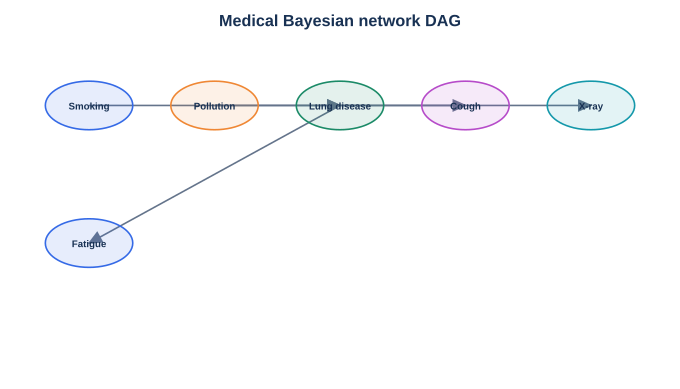

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

edges=[("Smoking","Lung"),("Pollution","Lung"),("Lung","Cough"),
       ("Lung","Xray"),("Lung","Fatigue")]
G=nx.DiGraph(edges)
# P(variable=1) or rows indexed by parent states (0/1).
cpd={
 "Smoking":np.array([.70,.30]),
 "Pollution":np.array([.80,.20]),
 "Lung":np.array([.98,.02,.92,.08,.88,.12,.70,.30]), # paired P(Lung=0),P(Lung=1) by S,P
 "Cough":np.array([.90,.10,.20,.80]),                 # paired by Lung
 "Xray":np.array([.95,.05,.10,.90]),
 "Fatigue":np.array([.85,.15,.30,.70])
}
# Check that each conditional column is a valid binary distribution.
for node,values in cpd.items():
    pairs=values.reshape(-1,2)
    assert np.allclose(pairs.sum(axis=1),1),f"Invalid CPD for {node}"
    print(f"{node}: {len(pairs)} valid conditional distribution(s)")
print("Local conditional independencies: Cough ⟂ Xray ⟂ Fatigue | Lung; "
      "Smoking ⟂ Pollution before observing Lung.")

# pgmpy validation when the optional dependency is present.
try:
    from pgmpy.models import DiscreteBayesianNetwork
    from pgmpy.factors.discrete import TabularCPD
    model=DiscreteBayesianNetwork(edges)
    model.add_cpds(
        TabularCPD("Smoking",2,[[.70],[.30]]),
        TabularCPD("Pollution",2,[[.80],[.20]]),
        TabularCPD("Lung",2,[[.98,.92,.88,.70],[.02,.08,.12,.30]],
                   evidence=["Smoking","Pollution"],evidence_card=[2,2]),
        TabularCPD("Cough",2,[[.90,.20],[.10,.80]],evidence=["Lung"],evidence_card=[2]),
        TabularCPD("Xray",2,[[.95,.10],[.05,.90]],evidence=["Lung"],evidence_card=[2]),
        TabularCPD("Fatigue",2,[[.85,.30],[.15,.70]],evidence=["Lung"],evidence_card=[2])
    )
    print("pgmpy check_model():",model.check_model())
except ImportError:
    print("pgmpy is not installed; the binary CPDs above were validated with NumPy.")

pos={"Smoking":(-1,1),"Pollution":(1,1),"Lung":(0,0),"Cough":(-1,-1),"Xray":(0,-1),"Fatigue":(1,-1)}
plt.figure(figsize=(7,4))
nx.draw_networkx(G,pos,with_labels=True,node_size=2300,node_color="#d9edf7",
                 arrowsize=20,font_size=9)
plt.title("Medical diagnosis Bayesian network");plt.axis("off");plt.show()
print("Active trails from Smoking before evidence:",nx.descendants(G,"Smoking"))
print("Given Lung disease, each symptom node is separated from its causes (d-separation).")